## K-Means Clustering - Customer Segmentation

**Overview**<br>
Data is downloaded from - https://archive.ics.uci.edu/ml/datasets/online+retail

The steps are broadly:
1. Read and understand the data
2. Clean the data
3. Prepare the data for modelling
4. Modelling
5. Final analysis and recommendations

# 1. Read and visualise the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import datetime as dt

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# read the dataset
retail_df = pd.read_excel("data/retail.xlsx")
retail_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
# basics of the df
retail_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# 2. Clean the data

In [168]:
# missing values
round(100*(retail_df.isnull().sum())/len(retail_df), 2)

InvoiceNo      0.0
StockCode      0.0
Description    0.0
Quantity       0.0
InvoiceDate    0.0
UnitPrice      0.0
CustomerID     0.0
Country        0.0
amount         0.0
diff           0.0
dtype: float64

In [172]:
retail_df["Description"]=retail_df["Description"].fillna(retail_df["Description"].mode()[0])
# drop all rows having missing values in customer ID.

retail_df=retail_df.dropna(subset=["CustomerID"])
retail_df.shape

(406829, 10)

In [174]:
retail_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,amount,diff
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373 days 04:24:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,373 days 04:24:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00


In [176]:
# new column: amount 
retail_df['amount'] = retail_df['Quantity']*retail_df['UnitPrice']
retail_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,amount,diff
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373 days 04:24:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,373 days 04:24:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00


# 3. Prepare the data for modelling

- R (Recency): Number of days since last purchase
- F (Frequency): Number of tracsactions
- M (Monetary): Total amount of transactions (revenue contributed)

In [180]:
# monetary
amount = retail_df.groupby('CustomerID')['amount'].sum()
amount = amount.reset_index()
amount.head()

,CustomerID,amount
0,12346.0,0.00
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40


In [182]:
# frequency
# count function gets the count of each item
frequency = retail_df.groupby('CustomerID')['InvoiceNo'].nunique()
frequency = frequency.reset_index()
frequency.columns = ['CustomerID', 'frequency']
frequency.head()

,CustomerID,frequency
0,12346.0,2
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1


In [184]:
# merge the two dfs
grouped_df = pd.merge(amount, frequency, on='CustomerID', how='inner')
grouped_df.head()

,CustomerID,amount,frequency
0,12346.0,0.00,2
1,12347.0,4310.00,7
2,12348.0,1797.24,4
3,12349.0,1757.55,1
4,12350.0,334.40,1


In [186]:
# recency
# convert to datetime

# retail_df['InvoiceDate'] = pd.to_datetime(retail_df['InvoiceDate'], format='%d-%m-%Y %H:%M')

In [188]:
# compute the max date
max_date = max(retail_df['InvoiceDate'])
max_date

Timestamp('2011-12-09 12:50:00')

In [189]:
# compute the diff
retail_df['diff'] = max_date - retail_df['InvoiceDate']
retail_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,amount,diff
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373 days 04:24:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,373 days 04:24:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00


In [190]:
# recency
last_purchase = retail_df.groupby('CustomerID')['diff'].min()
last_purchase = last_purchase.reset_index()
last_purchase.head()

,CustomerID,diff
0,12346.0,325 days 02:33:00
1,12347.0,1 days 20:58:00
2,12348.0,74 days 23:37:00
3,12349.0,18 days 02:59:00
4,12350.0,309 days 20:49:00


In [194]:
# merge
grouped_df = pd.merge(grouped_df, last_purchase, on='CustomerID', how='inner')
grouped_df.columns = ['CustomerID', 'amount', 'frequency', 'recency']
grouped_df.head()

,CustomerID,amount,frequency,recency
0,12346.0,0.00,2,325 days 02:33:00
1,12347.0,4310.00,7,1 days 20:58:00
2,12348.0,1797.24,4,74 days 23:37:00
3,12349.0,1757.55,1,18 days 02:59:00
4,12350.0,334.40,1,309 days 20:49:00


In [196]:
# number of days only
grouped_df['recency'] = grouped_df['recency'].dt.days
grouped_df.head()

,CustomerID,amount,frequency,recency
0,12346.0,0.00,2,325
1,12347.0,4310.00,7,1
2,12348.0,1797.24,4,74
3,12349.0,1757.55,1,18
4,12350.0,334.40,1,309


In [198]:
# rescaling
rfm_df = grouped_df[['amount', 'frequency', 'recency']]

# instantiate
scaler = StandardScaler()

# fit_transform
rfm_df_scaled = scaler.fit_transform(rfm_df)
rfm_df_scaled.shape

(4372, 3)

In [200]:
rfm_df_scaled = pd.DataFrame(rfm_df_scaled)
rfm_df_scaled.columns = ['amount', 'frequency', 'recency']
rfm_df_scaled.head()

,amount,frequency,recency
0,-0.231001,-0.329362,2.322023
1,0.293432,0.206102,-0.893733
2,-0.012316,-0.115176,-0.169196
3,-0.017146,-0.436455,-0.725005
4,-0.190312,-0.436455,2.163220


# 4. Modelling

In [203]:
# k-means with some arbitrary k
kmeans = KMeans(n_clusters=4, max_iter=50)
kmeans.fit(rfm_df_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,50
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [205]:
kmeans.labels_

array([0, 1, 1, ..., 1, 1, 1], dtype=int32)

In [207]:
# help(KMeans)

## Finding the Optimal Number of Clusters

### Elbow Curve Method

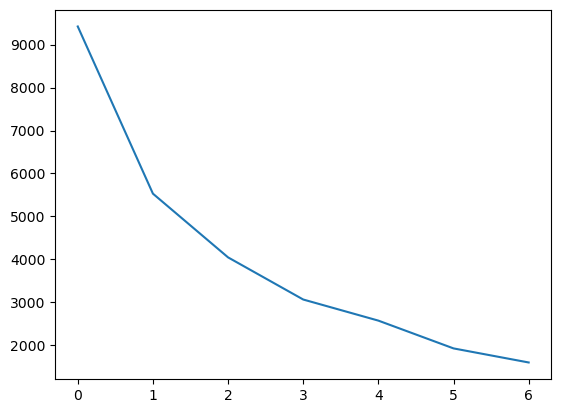

In [210]:
# elbow-curve
ssd = []
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]
for num_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50)
    kmeans.fit(rfm_df_scaled)
    
    ssd.append(kmeans.inertia_)
    
# plot the SSDs for each n_clusters
# ssd
plt.plot(ssd)

### Silhouette Analysis

$$\text{silhouette score}=\frac{p-q}{max(p,q)}$$

$p$ is the mean distance to the points in the nearest cluster that the data point is not a part of

$q$ is the mean intra-cluster distance to all the points in its own cluster.

* The value of the silhouette score range lies between -1 to 1. 

* A score closer to 1 indicates that the data point is very similar to other data points in the cluster, 

* A score closer to -1 indicates that the data point is not similar to the data points in its cluster.

In [212]:
# silhouette analysis
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for num_clusters in range_n_clusters:
    
    # intialise kmeans
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50)
    kmeans.fit(rfm_df_scaled)
    
    cluster_labels = kmeans.labels_
    
    # silhouette score
    silhouette_avg = silhouette_score(rfm_df_scaled, cluster_labels)
    print("For n_clusters={0}, the silhouette score is {1}".format(num_clusters, silhouette_avg))
    
    

For n_clusters=2, the silhouette score is 0.8953127225457423
For n_clusters=3, the silhouette score is 0.7223052192394132
For n_clusters=4, the silhouette score is 0.5806756067519812
For n_clusters=5, the silhouette score is 0.615110972451533
For n_clusters=6, the silhouette score is 0.510872787908364
For n_clusters=7, the silhouette score is 0.4857790231887972
For n_clusters=8, the silhouette score is 0.4975336761755085


In [214]:
# final model with k=3
kmeans = KMeans(n_clusters=3, max_iter=50)
kmeans.fit(rfm_df_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,50
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [215]:
kmeans.labels_

array([0, 2, 2, ..., 2, 2, 2], dtype=int32)

In [216]:
# assign the label
grouped_df['cluster_id'] = kmeans.labels_
grouped_df.head()

,CustomerID,amount,frequency,recency,cluster_id
0,12346.0,0.00,2,325,0
1,12347.0,4310.00,7,1,2
2,12348.0,1797.24,4,74,2
3,12349.0,1757.55,1,18,2
4,12350.0,334.40,1,309,0


<Axes: xlabel='cluster_id', ylabel='amount'>

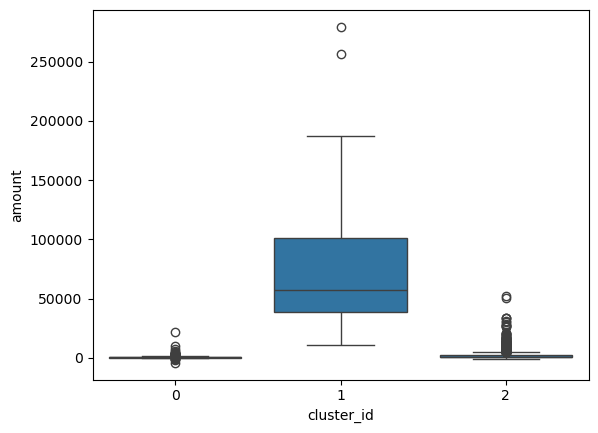

In [217]:
# plot
sns.boxplot(x='cluster_id', y='amount', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high monetary customers.</i><br>
    * <i> Cluster <code>0</code> and <code>1</code> has high overlap.</i><br>
    </div>
</div>

<Axes: xlabel='cluster_id', ylabel='frequency'>

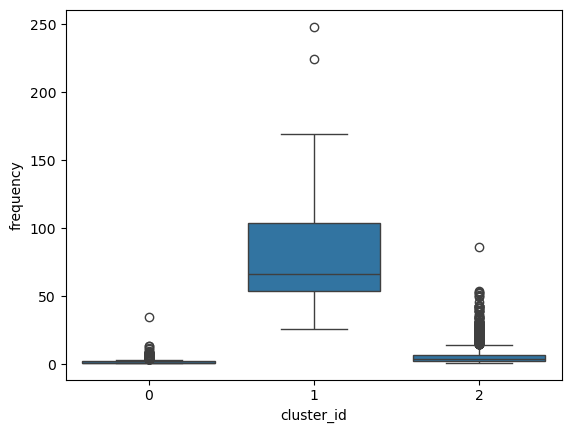

In [219]:
sns.boxplot(x='cluster_id', y='frequency', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high frequency customers.</i><br>
    * <i> Cluster <code>0</code> and <code>1</code> has high overlap.</i><br>
    </div>
</div>

<Axes: xlabel='cluster_id', ylabel='recency'>

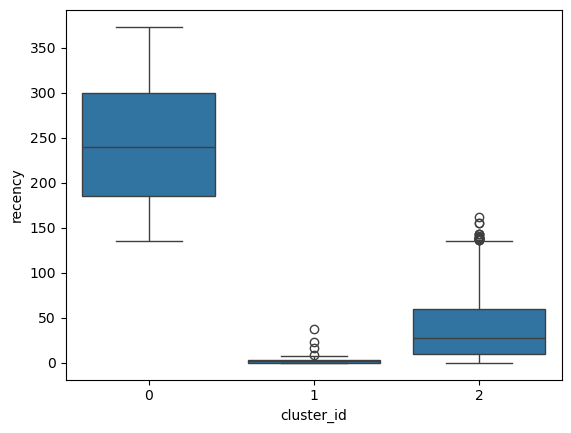

In [221]:
sns.boxplot(x='cluster_id', y='recency', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high recency customers in the sense that they recently visited the store/shop.</i><br>
    * <i> Cluster <code>0</code> represents least recent.</i><br>
    </div>
</div>

# 5. Treating the Outliers

In [230]:
grouped_df.describe()

,CustomerID,amount,frequency,recency,cluster_id
count,4372.000000,4372.000000,4372.000000,4372.000000,4372.000000
mean,15299.677722,1898.459701,5.075480,91.047118,1.486962
std,1722.390705,8219.345141,9.338754,100.765435,0.870506
min,12346.000000,-4287.630000,1.000000,0.000000,0.000000
25%,13812.750000,293.362500,1.000000,16.000000,0.000000
50%,15300.500000,648.075000,3.000000,49.000000,2.000000
75%,16778.250000,1611.725000,5.000000,142.000000,2.000000
max,18287.000000,279489.020000,248.000000,373.000000,2.000000


{'whiskers': [<matplotlib.lines.Line2D at 0x16863a150>,
 'caps': [<matplotlib.lines.Line2D at 0x168639c10>,
 'boxes': [<matplotlib.lines.Line2D at 0x1686392b0>],
 'medians': [<matplotlib.lines.Line2D at 0x168638920>],
 'fliers': [<matplotlib.lines.Line2D at 0x1686382f0>],
 'means': []}

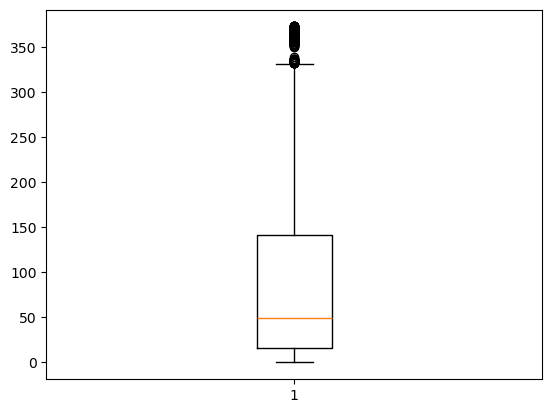

In [233]:
plt.boxplot(grouped_df['recency'])

{'whiskers': [<matplotlib.lines.Line2D at 0x175dc2990>,
 'caps': [<matplotlib.lines.Line2D at 0x175dc01d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x175dc0830>],
 'medians': [<matplotlib.lines.Line2D at 0x175dc27b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x175dc2ea0>],
 'means': []}

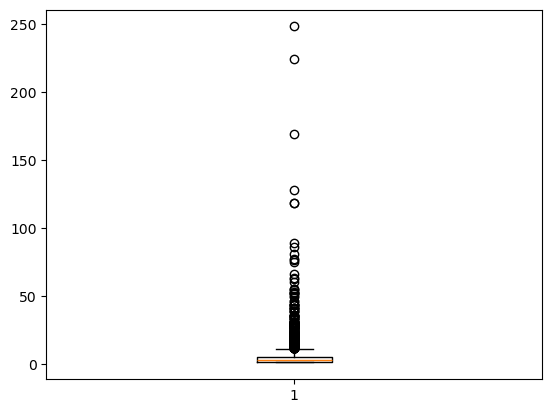

In [235]:
plt.boxplot(grouped_df['frequency'])

{'whiskers': [<matplotlib.lines.Line2D at 0x176f52000>,
 'caps': [<matplotlib.lines.Line2D at 0x176f53e30>,
 'boxes': [<matplotlib.lines.Line2D at 0x176f51250>],
 'medians': [<matplotlib.lines.Line2D at 0x17ad90d10>],
 'fliers': [<matplotlib.lines.Line2D at 0x17ad91be0>],
 'means': []}

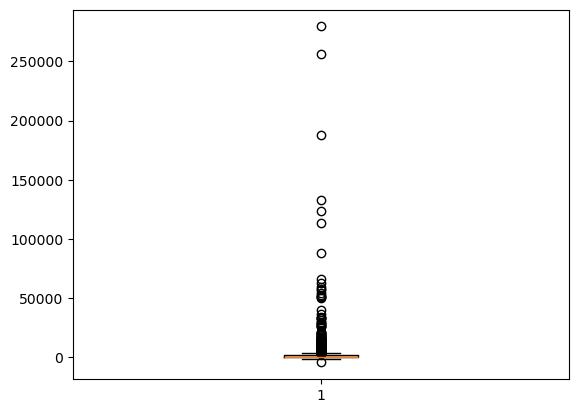

In [237]:
plt.boxplot(grouped_df['amount'])

In [239]:
# two types of outliers:
# - statistical
# - domain specific

In [241]:
# removing (statistical) outliers
Q1 = grouped_df.amount.quantile(0.10)
Q3 = grouped_df.amount.quantile(0.90)
IQR = Q3 - Q1
grouped_df = grouped_df[(grouped_df.amount >= Q1 - 1.5*IQR) & (grouped_df.amount <= Q3 + 1.5*IQR)]

# outlier treatment for recency
Q1 = grouped_df.recency.quantile(0.10)
Q3 = grouped_df.recency.quantile(0.90)
IQR = Q3 - Q1
grouped_df = grouped_df[(grouped_df.recency >= Q1 - 1.5*IQR) & (grouped_df.recency <= Q3 + 1.5*IQR)]

# outlier treatment for frequency
Q1 = grouped_df.frequency.quantile(0.10)
Q3 = grouped_df.frequency.quantile(0.90)
IQR = Q3 - Q1
grouped_df = grouped_df[(grouped_df.frequency >= Q1 - 1.5*IQR) & (grouped_df.frequency <= Q3 + 1.5*IQR)]

In [243]:
# 2. rescaling
rfm_df = grouped_df[['amount', 'frequency', 'recency']]

# instantiate
scaler = StandardScaler()

# fit_transform
rfm_df_scaled = scaler.fit_transform(rfm_df)
rfm_df_scaled.shape

(4209, 3)

In [245]:
rfm_df_scaled = pd.DataFrame(rfm_df_scaled)
rfm_df_scaled.columns = ['amount', 'frequency', 'recency']
rfm_df_scaled.head()

,amount,frequency,recency
0,-0.844245,-0.498797,2.280654
1,2.423353,0.801164,-0.919107
2,0.518321,0.021187,-0.198173
3,0.488230,-0.758789,-0.751218
4,-0.590722,-0.758789,2.122641


# 6. Modelling

## Finding the Optimal Number of Clusters

### SSD

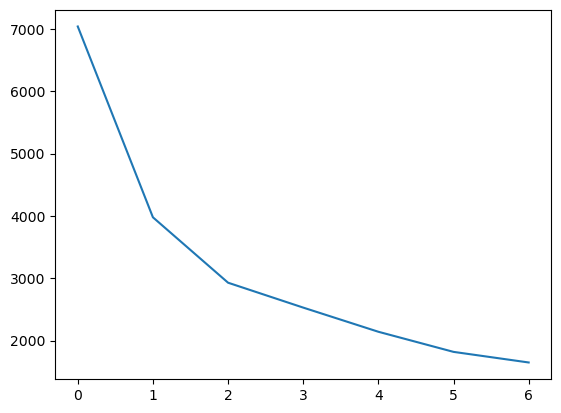

In [249]:
# elbow-curve/SSD
ssd = []
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]
for num_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50)
    kmeans.fit(rfm_df_scaled)
    
    ssd.append(kmeans.inertia_)
    
# plot the SSDs for each n_clusters
# ssd
plt.plot(ssd)

In [250]:
# silhouette analysis
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for num_clusters in range_n_clusters:
    
    # intialise kmeans
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50)
    kmeans.fit(rfm_df_scaled)
    
    cluster_labels = kmeans.labels_
    
    # silhouette score
    silhouette_avg = silhouette_score(rfm_df_scaled, cluster_labels)
    print("For n_clusters={0}, the silhouette score is {1}".format(num_clusters, silhouette_avg))
    
    

For n_clusters=2, the silhouette score is 0.4982754490289783
For n_clusters=3, the silhouette score is 0.49030867779024295
For n_clusters=4, the silhouette score is 0.4606060932748598
For n_clusters=5, the silhouette score is 0.3976201961704013
For n_clusters=6, the silhouette score is 0.3949561990403435
For n_clusters=7, the silhouette score is 0.39682409690536696
For n_clusters=8, the silhouette score is 0.3892614266002447


In [252]:
# final model with k=3
kmeans = KMeans(n_clusters=3, max_iter=50)
kmeans.fit(rfm_df_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,50
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [253]:
kmeans.labels_

array([1, 0, 2, ..., 2, 0, 2], dtype=int32)

In [254]:
# assign the label
grouped_df['cluster_id'] = kmeans.labels_
grouped_df.head()

,CustomerID,amount,frequency,recency,cluster_id
0,12346.0,0.00,2,325,1
1,12347.0,4310.00,7,1,0
2,12348.0,1797.24,4,74,2
3,12349.0,1757.55,1,18,2
4,12350.0,334.40,1,309,1


In [255]:
grouped_df.cluster_id.value_counts()

cluster_id
2    2503
1    1051
0     655
Name: count, dtype: int64

<Axes: xlabel='cluster_id', ylabel='amount'>

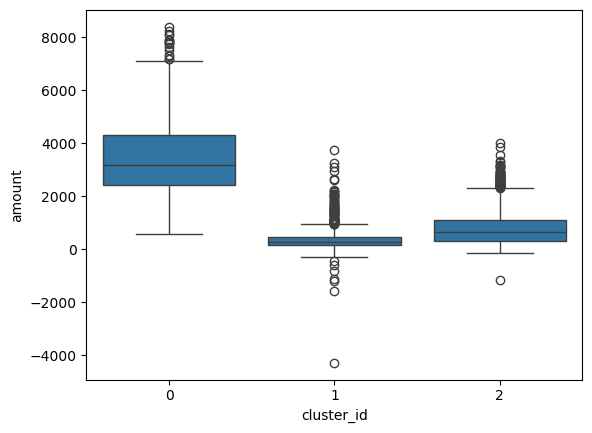

In [256]:
# plot
sns.boxplot(x='cluster_id', y='amount', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high monetary customers.</i><br>
    * <i> Cluster <code>1</code> represents least monetary customers.</i><br>
    </div>
</div>

<Axes: xlabel='cluster_id', ylabel='frequency'>

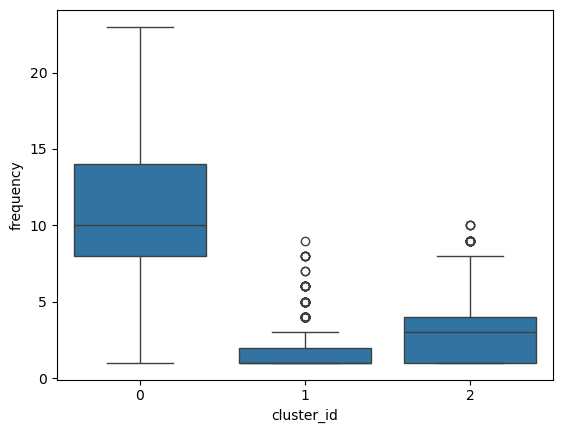

In [258]:
sns.boxplot(x='cluster_id', y='frequency', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high frequency customers.</i><br>
    * <i> Cluster <code>1</code> represents least frequency customers.</i><br>
    </div>
</div>

<Axes: xlabel='cluster_id', ylabel='recency'>

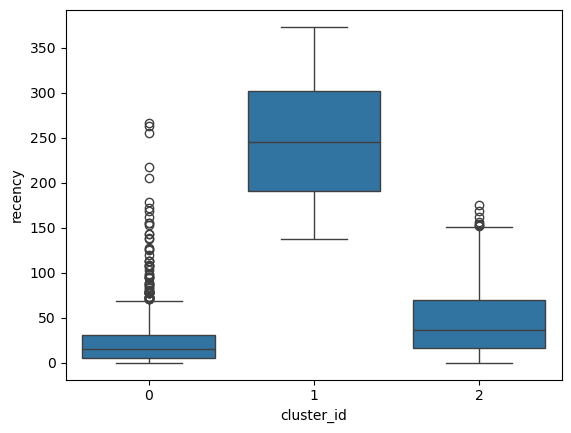

In [267]:
sns.boxplot(x='cluster_id', y='recency', data=grouped_df)

<div style="font-family:verdana;">
    <h3 style="font-family:verdana;">⭐Important Observations :</h3>
    <div class="alert alert-block alert-info">
    * <i> Cluster <code>2</code> represents high recency customers.</i><br>
    * <i> Cluster <code>1</code> represents least recency customers.</i><br>
    </div>
</div>

# Hierarchial clustering (Just for fun)

In [271]:
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import cut_tree

In [273]:
rfm_df_scaled

,amount,frequency,recency
0,-0.844245,-0.498797,2.280654
1,2.423353,0.801164,-0.919107
2,0.518321,0.021187,-0.198173
3,0.488230,-0.758789,-0.751218
4,-0.590722,-0.758789,2.122641
...,...,...,...
4204,-0.707325,-0.758789,1.806615
4205,-0.782972,-0.758789,0.848662
4206,-0.710357,-0.238805,-0.859852
4207,0.743974,3.141094,-0.899355


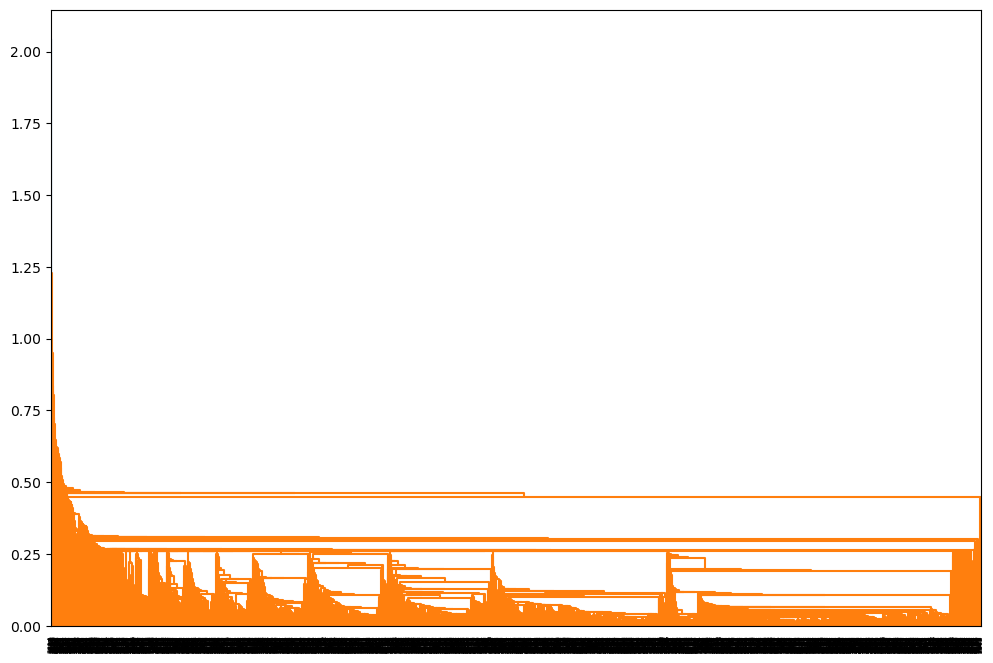

In [275]:
# Different ways to compute distance between two clusters
# Single Linkage

plt.figure(figsize=(12, 8))
mergings = linkage(rfm_df_scaled, method="single", metric="euclidean")
dendrogram(mergings)
plt.show()

In [ ]:

#complete linkage
plt.figure(figsize=(12, 8))
mergings = linkage(rfm_df_scaled, method="single", metric="euclidean")
dendrogram(mergings)
plt.show()

In [ ]:
cut_tree(mergings, n_clusters=3)

In [ ]:

lables = cut_tree(mergings, n_clusters=3).reshape(-1, )

lables

In [ ]:
# Create a colormap
colormap = np.array(['red', 'lime', 'black'])
 
# Plot the Original Classifications
plt.scatter(rfm_df_scaled.frequency, rfm_df_scaled.recency, c=colormap[lables])
plt.title('Agglomerative Clustering')

In [ ]:
 
# Plot the Original Classifications
plt.scatter(rfm_df_scaled.amount, rfm_df_scaled.recency, c=colormap[lables])
plt.title('Agglomerative Clustering')

In [164]:
lables

array([0, 0, 0, ..., 0, 0, 0])

In [166]:
grouped_df["cluster_id"]

0       2
1       0
2       1
3       1
4       2
       ..
4367    2
4368    2
4369    1
4370    0
4371    1
Name: cluster_id, Length: 4209, dtype: int32

In [ ]:
# hierarchial clustering is not suggested in such cases.


# we picked the data set
# 2. we cleaned and formatted it.
# 3. created patters like monetary,frequencya and receny for the data for better customer segmentation.
# 4. Applied k means clustering with random value of K and created clusters.
# 5. cross verified the correct number of clusters with elbow method or shilloute score.
# 6. again applied the K means clustering with better value of K.
# 7. Done cluster evaluation while plotting the box plot to check the overlapping of data.
# 8. Got to the know the data points of the clusters were highly overlapping.
# 9. Problem, was outliers so tried to remove it.
# 10. Implemented step 5 and 6 after the outliers removal and rescaling.
# 11. concluded the analysis.
# 12. Applied hierarchial clustering just for fun with simple and complete linkage.
# 13. decided the cut tress from the previous reference  of K means.